In [1]:
import pandas as pd 
import seaborn as sns 
from matplotlib import pyplot as plt

In [33]:
df=pd.read_csv('ad_spend.csv')
df.head()

,Ad Spend ($),Season,Revenue ($)
0,463,Monsoon,440
1,158,Winter,297
2,328,Monsoon,214
3,322,Monsoon,48
4,726,Winter,1048


In [11]:
g = df.groupby('Season').mean()
g

,Ad Spend ($),Revenue ($)
Season,,
Monsoon,517.643836,423.150685
Summer,573.836066,689.360656
Winter,552.560606,826.530303


(array([0, 1, 2]),
 [Text(0, 0, 'Monsoon'), Text(1, 0, 'Summer'), Text(2, 0, 'Winter')])

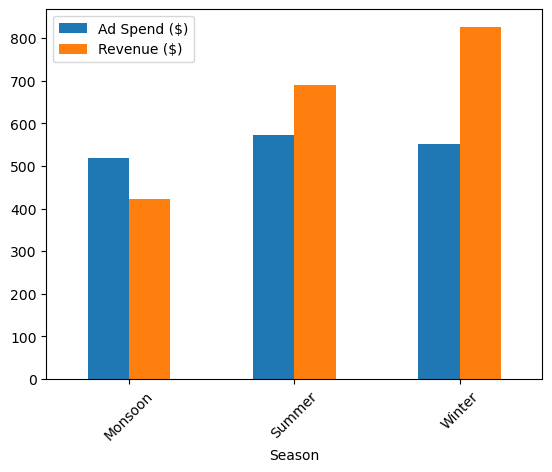

In [12]:
g.plot(kind='bar')
plt.xticks(rotation=45)

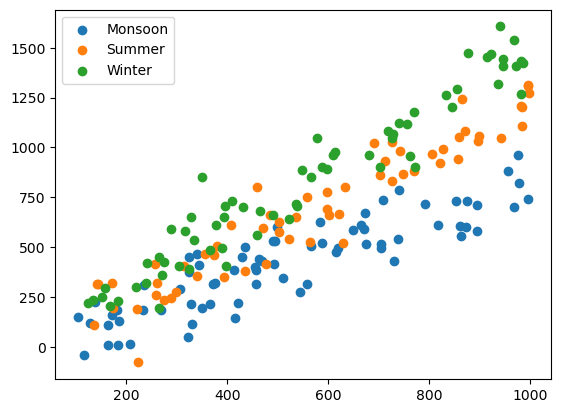

In [17]:
for season, subdf in df.groupby('Season'):
    plt.scatter(subdf['Ad Spend ($)'],subdf['Revenue ($)'],label=season)
    plt.legend()

In [19]:
from sklearn.model_selection import train_test_split

df_encoded=pd.get_dummies(data=df,columns=["Season"],drop_first=True)
df_encoded.head()

,Ad Spend ($),Revenue ($),Season_Summer,Season_Winter
0,463,440,False,False
1,158,297,False,True
2,328,214,False,False
3,322,48,False,False
4,726,1048,False,True


In [20]:
X=df_encoded.drop('Revenue ($)',axis=1)
y=df['Revenue ($)']

X_train, X_test, y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=3)

### Using linear Regresssion

In [21]:
from sklearn.linear_model import LinearRegression 

model= LinearRegression()
model.fit(X_train,y_train)
model.score(X_test,y_test)


0.8812217553316471

### Decision Tree Regressor

In [47]:
from sklearn.tree import DecisionTreeRegressor

model= DecisionTreeRegressor()
model.fit(X_train,y_train)
model.score(X_test,y_test)


0.8080528817549829

### Gradient Boosting Model

In [50]:
from sklearn.ensemble import GradientBoostingRegressor

model=GradientBoostingRegressor()
model.fit(X_train,y_train)
model.score(X_test,y_test)

0.8688108046493086

In [41]:
y_pred=model.predict(X_test)

df_eval=pd.DataFrame({
    "Actual" : y_test,
    "Predicted" : y_pred
})
df_eval

,Actual,Predicted
40,854,786.654203
51,538,525.227841
139,427,336.835620
197,10,110.569095
170,108,276.519541
82,866,991.444611
183,231,246.732422
46,834,993.887646
70,962,788.470326
100,717,616.317212


In [43]:
df_eval['% diff']= abs(df_eval['Actual']-df_eval['Predicted'])*100/df_eval['Actual']
df_eval

,Actual,Predicted,% diff
40,854,786.654203,7.885925
51,538,525.227841,2.374007
139,427,336.835620,21.115780
197,10,110.569095,1005.690951
170,108,276.519541,156.036612
82,866,991.444611,14.485521
183,231,246.732422,6.810572
46,834,993.887646,19.171181
70,962,788.470326,18.038428
100,717,616.317212,14.042230
